# Why Does Gradient Descent Slow Down?

Ivan Velev

## 1. Problem and questions

An optimizer is trying to find the minimum of a function. The three methods we will look at (Gradient Descent, Momentum and Newton's method) usually reach the same answer, but in a different number of iterations. In this notebook I will explain them and compare them across two experiments. We will use them on a simple example: the quadratic bowl function. The questions I will try to answer are:

1. How does $\kappa$ affect the number of iterations?
2. Which of these methods is the best, or is there one at all?
3. Does the step size limit $\eta < 2/\kappa$ from the proof hold in practice?

## 2. Background

The test function is the quadratic bowl:

$$f(x, y) = \tfrac{1}{2}\left(x^2 + \kappa y^2\right)$$

For a large $\kappa$, the bowl is squished along the y axis, where the curve is steeper, and stretched along the x axis, where the curve is flatter. The minimum we are searching for is at the point (0, 0):

$$x^* = (0, 0), \qquad f(x^*) = 0$$

Its gradient and Hessian both point to the same conclusion: the rate of change along the y axis is $\kappa$ times larger than along the x axis.

$$\nabla f(x, y) = \begin{pmatrix} x \\ \kappa y \end{pmatrix}
\qquad
H = \begin{pmatrix} 1 & 0 \\ 0 & \kappa \end{pmatrix}$$

The three methods we will look at are:

### Gradient Descent

It moves in the opposite direction to the slope. It works by finding the gradient of the function and taking a step towards the minimum. The step size is $\eta$, and it shouldn't be too large, or the method will not converge.

$$x_{k+1} = x_k - \eta \, \nabla f(x_k)$$

### Momentum

Its analogy is a ball rolling down a hill: with each iteration it picks up speed from the previous ones. The parameter $\beta$ controls how much of the previous step is kept.

$$x_{k+1} = x_k - \eta \, \nabla f(x_k) + \beta \,(x_k - x_{k-1})$$

### Newton's method

Instead of using just the first derivative like Gradient Descent, it also uses the second, to know how far the minimum is from the current position. This is done using the Hessian matrix. In our case it solves the problem in just one iteration, because it approximates the function as a quadratic and ours already is one.

$$x_{k+1} = x_k - H^{-1} \nabla f(x_k)$$

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import optimizers as op

## 3. Why does gradient descent slow down?

The gradient of our function is:

$$\nabla f(x, y) = \begin{pmatrix} x \\ \kappa y \end{pmatrix}$$

This also matches the numerical gradient approximation. That means our position after one step is:

$$x_{k+1} = x_k - \eta x_k, \qquad y_{k+1} = y_k - \eta\kappa y_k$$

Or, factoring out $x_k$ and $y_k$:

$$x_{k+1} = (1 - \eta)\, x_k, \qquad y_{k+1} = (1 - \eta\kappa)\, y_k$$

This means that each new iterate is the previous one multiplied by a constant. So the position after $k$ steps is:

$$x_k = (1 - \eta)^k x_0, \qquad y_k = (1 - \eta\kappa)^k y_0$$

where $x_0$ and $y_0$ are the starting position.

For $x$ to converge to 0 as $k$ grows large, we need the following condition:

$$|1 - \eta| < 1 \;\Longleftrightarrow\; 0 < \eta < 2$$

And for $y$:

$$|1 - \eta\kappa| < 1 \;\Longleftrightarrow\; 0 < \eta < \frac{2}{\kappa}$$

Because we assume $\kappa$ is a large number, $2 > 2/\kappa$. Both conditions must hold, so the step size has to be smaller than $2/\kappa$.

Let's choose $\eta = 1/\kappa$. Then the formula becomes:

$$x_k = \left(1 - \tfrac{1}{\kappa}\right)^k x_0, \qquad y_k = 0 \text{ for } k \ge 1$$

So the distance from the solution at step $k$ is at most:

$$\|(x_k, y_k)\| \le \left(1 - \tfrac{1}{\kappa}\right)^k \|(x_0, y_0)\|$$



In [ ]:
predicted = np.log(1e-8) / np.log(1 - 1/100)
x, hist = op.gradient_descent(lambda p: op.quadratic_grad(p, 100), np.array([1.0, 1.0]), step=1/100)
print("predicted:", predicted)
print("actual:", len(hist) - 1)

predicted: 1832.8423062135541
actual: 1833


Comparing our Gradient Descent implementation with the predicted number of steps, we get almost the same answer (1833 vs 1832.8). The prediction comes from the exponential decay $(1 - 1/\kappa)^k$ of the position after $k$ iterations, so this confirms the rate from the proof.

## 4. Why Newton's method needs one step

$$H^{-1} = \begin{pmatrix} 1 & 0 \\ 0 & 1/\kappa \end{pmatrix}$$

$$H^{-1}\nabla f(x_k, y_k) = \begin{pmatrix} 1 & 0 \\ 0 & 1/\kappa \end{pmatrix}\begin{pmatrix} x_k \\ \kappa y_k \end{pmatrix} = \begin{pmatrix} x_k \\ y_k \end{pmatrix}$$

$$\begin{pmatrix} x_{k+1} \\ y_{k+1} \end{pmatrix} = \begin{pmatrix} x_k \\ y_k \end{pmatrix} - \begin{pmatrix} x_k \\ y_k \end{pmatrix} = \begin{pmatrix} 0 \\ 0 \end{pmatrix}$$

So it finds the minimum after a single step for any $\kappa$ and any starting point, because our function is a quadratic.


## 5. Momentum (cited result)

For momentum we do not prove the rate here. Instead we use the result from Polyak (1964). With the parameters

$$\eta = \frac{4}{(\sqrt{\kappa} + 1)^2}, \qquad \beta = \left(\frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1}\right)^2$$

the distance to the minimum shrinks like

$$\|x_k - x^*\| \approx \left(\frac{\sqrt{\kappa} - 1}{\sqrt{\kappa} + 1}\right)^k \|x_0 - x^*\|$$

For $\kappa = 100$ this factor is about 0.82, compared to 0.99 for gradient descent. That means momentum approaches the minimum much faster than gradient descent: it removes about 18% of the remaining distance per step instead of 1%.

The difference is that gradient descent's factor depends on $\kappa$, while momentum's depends on $\sqrt{\kappa}$. So when $\kappa$ gets large, momentum's factor stays further from 1, and it slows down much less.

We check this prediction in Experiment 1.

## 6. Experiment 1: effect of $\kappa$

How the number of iterations changes with respect to $\kappa$.

kappa      GD  Momentum  Newton
    1       1         1       1
   10     175        38       1
  100    1833       143       1
 1000   18412       510       1


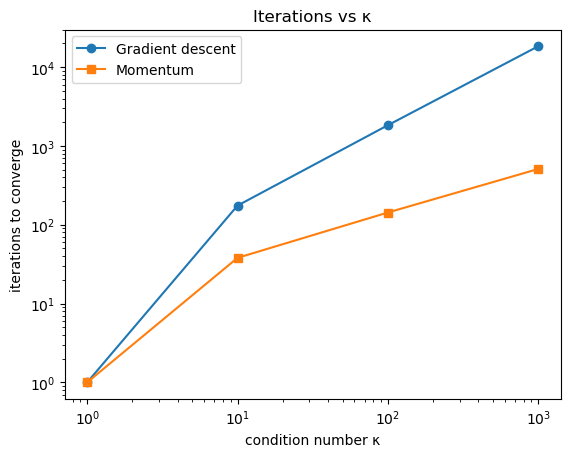

In [3]:
def count_iterations(kappa):
    """Run all three methods on the bowl with this kappa, return their iteration counts."""
    start = np.array([1.0, 1.0])
    grad = lambda p: op.quadratic_grad(p, kappa)
    hess = lambda p: op.quadratic_hess(p, kappa)

    # Polyak's optimal momentum parameters (Polyak, 1964)
    r = np.sqrt(kappa)
    mom_step = 4 / (r + 1) ** 2
    beta = ((r - 1) / (r + 1)) ** 2

    _, gd = op.gradient_descent(grad, start, step=1 / kappa, max_iter=50000)
    _, mom = op.momentum(grad, start, step=mom_step, beta=beta, max_iter=50000)
    _, newton = op.newton_method(grad, hess, start)
    return len(gd) - 1, len(mom) - 1, len(newton) - 1


kappas = [1, 10, 100, 1000]
results = [count_iterations(k) for k in kappas]

print("kappa      GD  Momentum  Newton")
for k, (gd, mom, newton) in zip(kappas, results):
    print(f"{k:>5}  {gd:>6}  {mom:>8}  {newton:>6}")

gd_iters = [r[0] for r in results]
mom_iters = [r[1] for r in results]
plt.loglog(kappas, gd_iters, "o-", label="Gradient descent")
plt.loglog(kappas, mom_iters, "s-", label="Momentum")
plt.xlabel("condition number κ")
plt.ylabel("iterations to converge")
plt.title("Iterations vs κ")
plt.legend()
plt.show()